### Library Importation

In [1]:
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
import time

from pathlib import Path
from PIL import Image

from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

### Load dataset

In [2]:
# Path to CSV files
data_path = Path("../data")

# Load datasets
train_df = pd.read_csv(data_path / "train.csv")
validation_df = pd.read_csv(data_path / "validation.csv")
test_df = pd.read_csv(data_path / "test.csv")

# Display dataset sizes
print("Training:", len(train_df))
print("Validation:", len(validation_df))
print("Testing:", len(test_df))

Training: 5806
Validation: 1659
Testing: 830


In [3]:
# Display first five training records
train_df.head()

,image_path,label
0,..\processed_dataset\bacterial_leaf_blight\950...,bacterial_leaf_blight
1,..\processed_dataset\brown_spot\600.jpg,brown_spot
2,..\processed_dataset\healthy\343.jpg,healthy
3,..\processed_dataset\tungro_disease\836.jpg,tungro_disease
4,..\processed_dataset\rice_blast\340.jpg,rice_blast


In [4]:
def load_images(dataframe):

    images = []

    for image_path in dataframe["image_path"]:

        image = Image.open(image_path).convert("RGB")

        image_array = np.array(image)

        images.append(image_array)

    return np.array(images)


# Load images
X_train = load_images(train_df)
X_val = load_images(validation_df)
X_test = load_images(test_df)

# Load labels
y_train = train_df["label"].values
y_val = validation_df["label"].values
y_test = test_df["label"].values

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

Training shape: (5806, 128, 128, 3)
Validation shape: (1659, 128, 128, 3)
Testing shape: (830, 128, 128, 3)


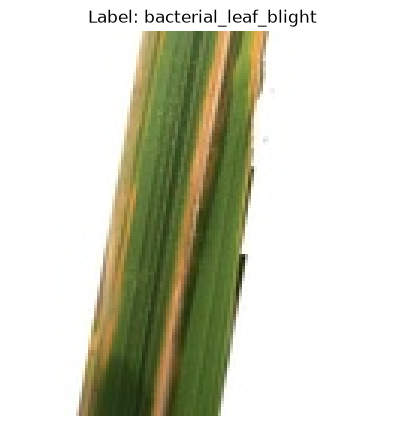

In [5]:
plt.figure(figsize=(5, 5))

plt.imshow(X_train[random.randint(0, 1000)])
plt.title(f"Label: {y_train[0]}")
plt.axis("off")

plt.show()

In [6]:
# Get the number of images
n_train = X_train.shape[0]
n_val = X_val.shape[0]
n_test = X_test.shape[0]

# Flatten images
X_train_flat = X_train.reshape(n_train, -1)
X_val_flat = X_val.reshape(n_val, -1)
X_test_flat = X_test.reshape(n_test, -1)

# Display shapes
print("Training:", X_train_flat.shape)
print("Validation:", X_val_flat.shape)
print("Testing:", X_test_flat.shape)

Training: (5806, 49152)
Validation: (1659, 49152)
Testing: (830, 49152)


### Feature Scaling

In [7]:
# Convert pixel values to float and normalize (feature scaling)
X_train_scaled = X_train_flat.astype(np.float32) / 255.0
X_val_scaled = X_val_flat.astype(np.float32) / 255.0
X_test_scaled = X_test_flat.astype(np.float32) / 255.0

# Check values
print("Minimum:", X_train_scaled.min())
print("Maximum:", X_train_scaled.max())

Minimum: 0.0
Maximum: 1.0


In [8]:
components = [10, 25, 50, 100, 200, 300, 400, 500, 600]

results = []

for n in components:
    print(f"Testing PCA components: {n}")

    # 1. PCA transformation Model
    pca_model = PCA(n_components=n, random_state=42)

    X_train_pca = pca_model.fit(X_train_scaled)

    explained_variance = pca_model.explained_variance_ratio_

    cumulative_variance = np.cumsum(explained_variance)
    
    print("Variance explained by first 10 components:")

    for i in range(min(5, len(explained_variance))):
        print(
            f"PC{i + 1}: {explained_variance[i]:.4f}"
        )

    print("." * 3)
    print(
        "Total variance explained:",
        cumulative_variance[-1]
    )

    X_train_pca = pca_model.transform(X_train_scaled)
    X_val_pca = pca_model.transform(X_val_scaled)
    X_test_pca = pca_model.transform(X_test_scaled)

    # 2. Logistic Regression Model
    print("Logistic Regression Model")
    lr_model = LogisticRegression(
        max_iter=4000,
        random_state=42
    )

    start_lr_time = time.time()
    lr_model.fit(X_train_pca, y_train)
    lr_time = time.time() - start_lr_time

    lr_train_acc = accuracy_score(y_train, lr_model.predict(X_train_pca))
    lr_val_acc = accuracy_score(y_val, lr_model.predict(X_val_pca))

    print("Duration Training: ", lr_time)
    print("Training accuracy: ", lr_train_acc)
    print("Validation accuracy: ", lr_val_acc)

    # 3. Neural Network Model
    print("Neural Network Model")

    nn_model = MLPClassifier(
        hidden_layer_sizes=(512, 256, 256, 128, 64),
        activation="relu",
        solver="adam",
        max_iter=100,
        random_state=42,
    )

    start_nn_time = time.time()
    nn_model.fit(X_train_pca, y_train)
    nn_time = time.time() - start_nn_time

    nn_train_acc = accuracy_score(y_train, nn_model.predict(X_train_pca))
    nn_val_acc = accuracy_score(y_val, nn_model.predict(X_val_pca))

    print("Duration Training: ", nn_time)
    print("Training accuracy: ", nn_train_acc)
    print("Validation accuracy: ", nn_val_acc)

    results.append({
        "n_components": n,
        "total variance explain": cumulative_variance[-1],

        "lr_train_accuracy": float(lr_train_acc),
        "lr_val_accuracy": float(lr_val_acc),
        "lr_training_time": float(lr_time),

        "nn_train_accuracy": float(nn_train_acc),
        "nn_val_accuracy": float(nn_val_acc),
        "nn_training_time": float(nn_time)
    })

    print("\n")

# Convert results into DataFrame
results_df = pd.DataFrame(results)
# Save results
results_df.to_csv(
    "pca_experiment_results.csv",
    index=False
)

print(results_df)

Testing PCA components: 10
Variance explained by first 10 components:
PC1: 0.6094
PC2: 0.0675
PC3: 0.0303
PC4: 0.0219
PC5: 0.0210
...
Total variance explained: 0.8110137
Logistic Regression Model
Duration Training:  0.8154258728027344
Training accuracy:  0.6029968997588702
Validation accuracy:  0.5858951175406871
Neural Network Model
Duration Training:  20.4262638092041
Training accuracy:  0.9633138132965897
Validation accuracy:  0.8468957203134418


Testing PCA components: 25
Variance explained by first 10 components:
PC1: 0.6094
PC2: 0.0675
PC3: 0.0303
PC4: 0.0219
PC5: 0.0210
...
Total variance explained: 0.87777555
Logistic Regression Model
Duration Training:  0.7811398506164551
Training accuracy:  0.690492593868412
Validation accuracy:  0.674502712477396
Neural Network Model
Duration Training:  19.62911295890808
Training accuracy:  0.9968997588701344
Validation accuracy:  0.8836648583484027


Testing PCA components: 50
Variance explained by first 10 components:
PC1: 0.6094
PC2: 0.0

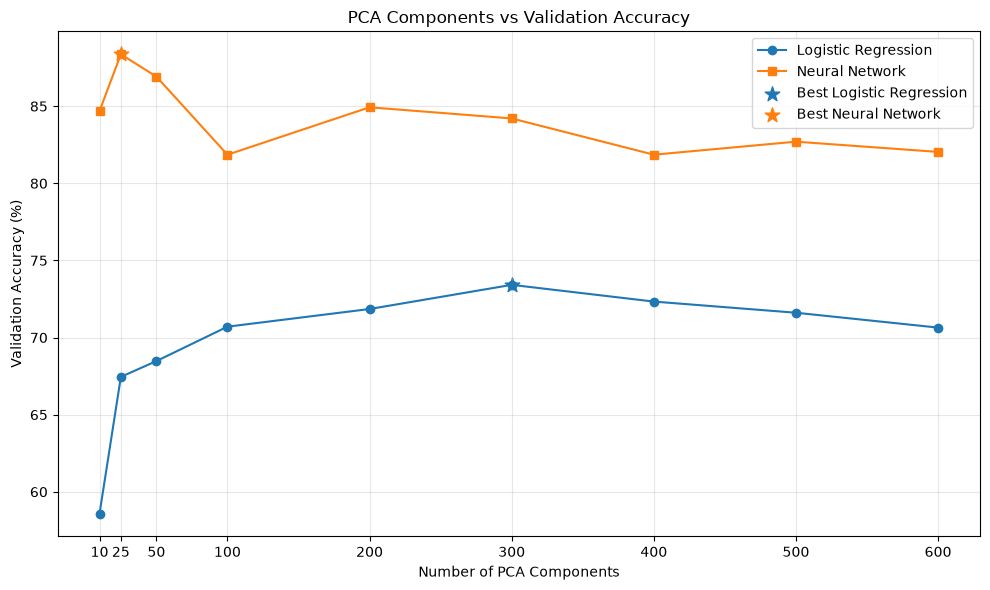

In [9]:
plt.figure(figsize=(10, 6))

plt.plot(
    results_df["n_components"],
    results_df["lr_val_accuracy"] * 100,
    marker="o",
    label="Logistic Regression"
)

plt.plot(
    results_df["n_components"],
    results_df["nn_val_accuracy"] * 100,
    marker="s",
    label="Neural Network"
)

# Highlight best results
lr_best = results_df.loc[
    results_df["lr_val_accuracy"].idxmax()
]

nn_best = results_df.loc[
    results_df["nn_val_accuracy"].idxmax()
]

plt.scatter(
    lr_best["n_components"],
    lr_best["lr_val_accuracy"] * 100,
    s=120,
    marker="*",
    label="Best Logistic Regression"
)

plt.scatter(
    nn_best["n_components"],
    nn_best["nn_val_accuracy"] * 100,
    s=120,
    marker="*",
    label="Best Neural Network"
)

plt.xlabel("Number of PCA Components")
plt.ylabel("Validation Accuracy (%)")
plt.title("PCA Components vs Validation Accuracy")

plt.xticks(components)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "pca_validation_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

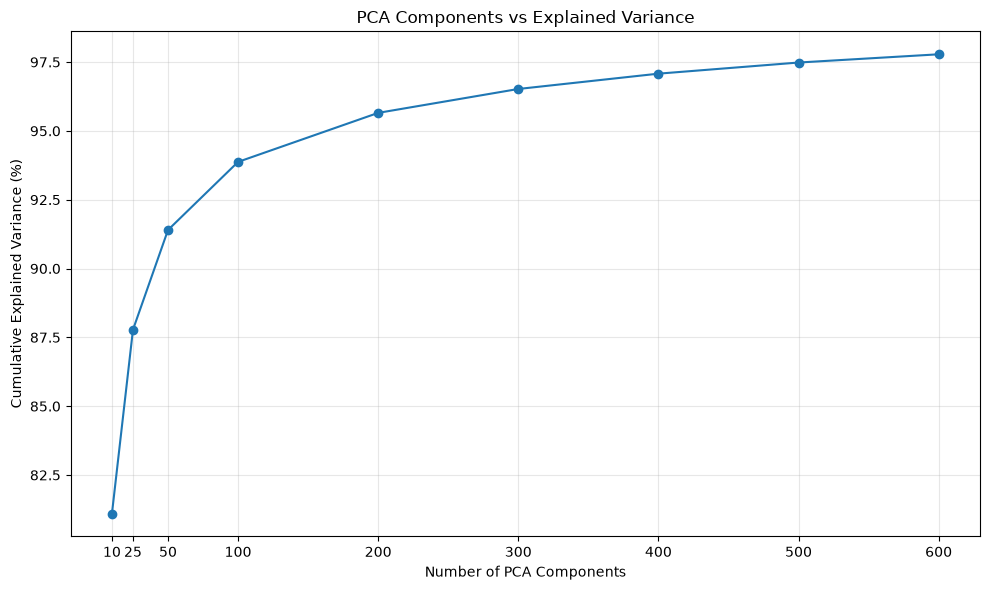

In [10]:
plt.figure(figsize=(10, 6))

plt.plot(
    results_df["n_components"],
    results_df["total variance explain"] * 100,
    marker="o"
)

plt.xlabel("Number of PCA Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA Components vs Explained Variance")

plt.xticks(components)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "pca_explained_variance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

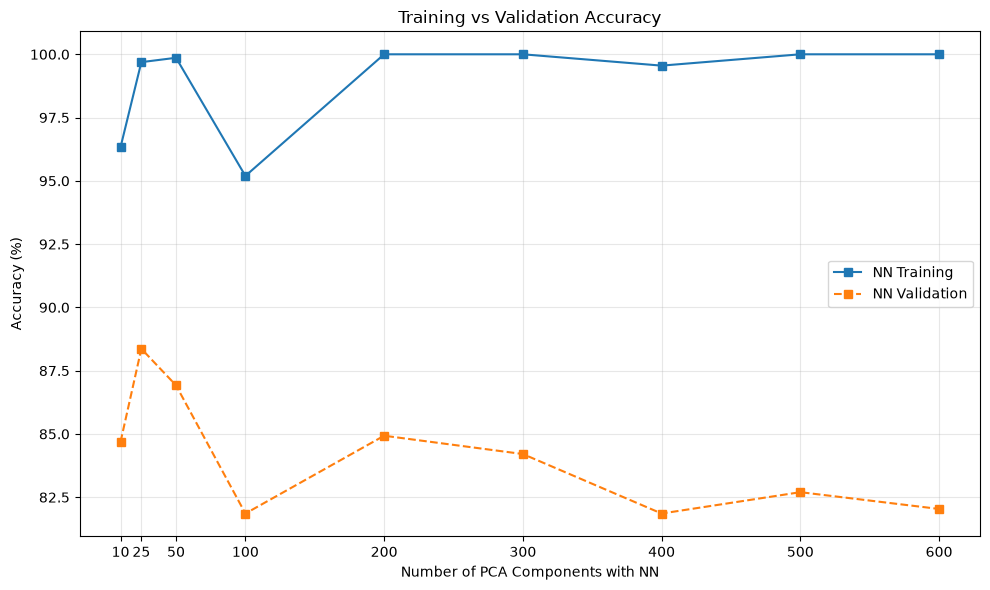

In [11]:
plt.figure(figsize=(10, 6))

plt.plot(
    results_df["n_components"],
    results_df["nn_train_accuracy"] * 100,
    marker="s",
    label="NN Training"
)

plt.plot(
    results_df["n_components"],
    results_df["nn_val_accuracy"] * 100,
    marker="s",
    linestyle="--",
    label="NN Validation"
)

plt.xlabel("Number of PCA Components with NN")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")

plt.xticks(components)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "pca_nn_train_validation_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

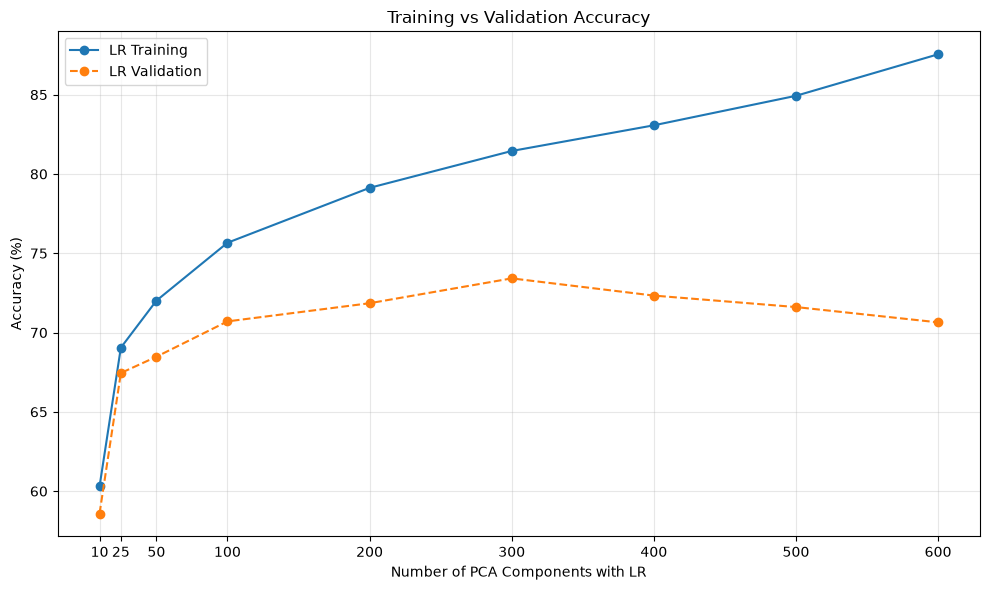

In [12]:
plt.figure(figsize=(10, 6))

plt.plot(
    results_df["n_components"],
    results_df["lr_train_accuracy"] * 100,
    marker="o",
    label="LR Training"
)

plt.plot(
    results_df["n_components"],
    results_df["lr_val_accuracy"] * 100,
    marker="o",
    linestyle="--",
    label="LR Validation"
)

plt.xlabel("Number of PCA Components with LR")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")

plt.xticks(components)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "pca_lr_train_validation_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()